# K-Means Project
by Benjamin Nelson

In this project, I will be using a K-Means algorithem to decrease the number of pixel colors in an image. I will have this be a k value for easy replication with more and less colors. 

The algorthem will fuction as follows:
1. Get image data, including pixels, and store this in a pandas/numpy data set.
2. Use the RGB data to find distances
3. Initalize k centers. I will be picking random centers on random pixels furthest apart.
4. Assign all points to a center. If any center without any points, randomly move it to a new point furthest away from other centers.
5. Move Centers.
6. Repeat steps 4 and 5 till convergence. 
7. Use center RGB to re-color rest of RGB in image based on what is in each centers group


## Part 1: Full code in Concise blocks

Here I throughly explain all the functions and put them into a single box to make re-running things faster.

In [435]:
import pandas as pd
import numpy as np
from PIL import Image, ImageOps
import math

"""
Function: randomSelection
-------------------------------------------
Inputs: 
    array: array with pure data in LoL formate (numpy)
    numberSelected: Number of points to be selected from the array
    seed: seed used for randomly generating the list
Outputs:
    returnArray: with a portion of the total size of the original
-------------------------------------------
First this makes a new array of the size wanted (numberSelected by columns).
Second it generates a random non-repeating list of indexes from the array
Finally it fills out the array
"""

def randomSelection(array, numberSelected, seed):
    
    columns = len(array[0])
    shape = (numberSelected, columns)
    returnArray = np.zeros(shape)

    numberInArray = len(array)

    #get list of random indexes to add to our list
    np.random.seed(seed)
    listToGrab = np.random.choice(numberInArray,numberSelected,replace=False)

    #add the indexes to our list
    for Newindex, arrayIndex in enumerate(listToGrab):
        for column in range(columns):
            returnArray[Newindex][column] = array[arrayIndex][column]
    
    return returnArray

"""
Function: calculateClosestCenter
-------------------------------------------
Inputs: 
    points: array of point data in LoL formate (numpy)
    centers: dataframe of all centers in LoD formate (pandas)
Outputs:
    Inertia: the squared distance from each point to it's closest center
    It also changes the labels in center to be filled with points that are closest to it
-------------------------------------------
First clears labels.
Second for each point find the distance to each center and only keep the best. 
Finally appends them to "lables" in the centers and get's inertia
"""

def calculateClosestCenter(points, centers):
    Inertia = 0

    #clear previous points in center array
    for centerIndex in range(len(centers)):
        centers.loc[centerIndex]["labels"] = []

    for pointIndex, point in enumerate(points):
        BestDistance = -1
        BestCenter = -1

        #must run al least once, min 1 center
        for CenterIndex in range(len(centers)):
            distance = 0
            for part in range(len(centers.loc[CenterIndex]["data"])):
                distance += (point[part]-centers.loc[CenterIndex]["data"][part])**2
            distance = math.sqrt(distance)
            if distance < BestDistance or BestDistance == -1:
                BestDistance = distance
                BestCenter = CenterIndex
        centers.loc[BestCenter]["labels"].append(pointIndex)
        Inertia += (BestDistance**2)
    return(Inertia)

"""
Function: random_center
-------------------------------------------
Inputs: 
    k: number of centers
    points: array of point data in LoL formate (numpy)
Outputs:
    centers: dataframe of k "random" centers in LoD formate (pandas)
-------------------------------------------
This funciton, k times, finds the furthist point that isn't already taken. It trakes taken with a temp point set.
It calles upon the FurthestPointFromCenters function to get this new center using the current centers and 
 the temp points - center points (they get deleated from the temp when used)
The very first instance is just the first point in the dataset for simplisity.
Returns a pandas dataFrame with the centers
"""

def random_center(k, points):
    centers = pd.DataFrame(columns = ["data","labels"])

    #temp points, to be removed as you go so there is no repeats
    tempPoints = points.copy()

    for i in range(k):
        #if it is the first one, just use first point in set
        if i == 0:
            center = pd.DataFrame(columns=["data", "labels"])
            center.loc[0] = [[],[]]
            for j in range(len(tempPoints[0])):
                center.loc[0]["data"].append(tempPoints[0][j])
            #delete used points so they don't get reused
            tempPoints = np.delete(tempPoints, 0, axis=0)
        else:
            center = FurthestPointFromCenters(tempPoints,centers)
            
            #delete used points so they don't get reused
            indexToRemove = np.where(tempPoints == center.loc[0]["data"])
            tempPoints = np.delete(tempPoints, indexToRemove, axis=0)
            
        centers = pd.concat([centers, center], ignore_index=True)
    return centers

"""
Function: FurthestPointFromCenters
-------------------------------------------
Inputs: 
    points: array of point data in LoL formate (numpy)
    centers: dataframe centers in LoD formate (pandas)
Outputs:
    center: a point in points that has the greatest combined distance from all other points
-------------------------------------------
This loops through each point and finds which one is furthest from it's closest center.
It does this by keeping trake of the furthest point (index of current furthest point) and it's distance.
When it finds something with greater distance it overrites the previous.
Finally it outputs the center in a pandas dataframe so it can be concatinated elsewhere
"""

def FurthestPointFromCenters(points,centers):
    furthest_point = 0
    furthest_distance = 0

    for pointIndex in range(len(points)):
        #ClosestCenterToPoint = -1
        ClosestCenterDistance = -1
        for centerIndex in range(len(centers)):
            distance = 0

            #looping through all posible data
            for part in range(len(points[pointIndex])):
                distance += (points[pointIndex][part]-centers.loc[centerIndex]["data"][part])**2
            distance = math.sqrt(distance)

            if distance < ClosestCenterDistance or ClosestCenterDistance == -1:
                ClosestCenterDistance = distance
                #ClosestCenterToPoint = centerIndex

        if ClosestCenterDistance > furthest_distance:
            furthest_distance = ClosestCenterDistance
            furthest_point = pointIndex
    
    #initalize and add all data
    center = pd.DataFrame(columns=["data", "labels"])
    center.loc[0] = [[],[]]

    for j in range(len(points[furthest_point])):
        center.loc[0]["data"].append(points[furthest_point][j])
    return center

"""
Function: adjustCenters
-------------------------------------------
Inputs: 
    arrayPoints: array of point data in LoL formate (numpy)
    centers: dataframe centers in LoD formate (pandas)
Outputs:
    Moved: Truth-Value on if anything moved from what was originally there
-------------------------------------------
Get a new center set, same size as the first that is cleared.
for each point, add it's distances to their corisponding new center,
divide by the number of points added per center.
If center got nothing, randomly assign it to a far point (use previous method)
If data not moving, return False Otherwise True
Always update oldData to newData even if no change
Safty clear labels incase anything else may cause it errors
"""

def adjustCenters(centers, arrayPoints):

    NewCenters = centers.copy()

    #Clearing all previous distances
    for index in range(len(NewCenters)):
        for part in range(len(NewCenters.loc[index]["data"])):
            NewCenters.loc[index]["data"][part] = 0

    DeadCenters = [] #list of indexs that are dead
    UsableCenters = pd.DataFrame(columns=["data", "labels"])  #temp df incase dead centers. has all needed data

    for index in range(len(NewCenters)):
        if (len(NewCenters.loc[index]["labels"]) == 0):
            DeadCenters.append(index)
        else:
            #add all the totals from the matched points by each part and divide
            for part in range(len(NewCenters.loc[index]["data"])):
                for pointIndex in NewCenters.loc[index]["labels"]:
                    NewCenters.loc[index]["data"][part] += arrayPoints[pointIndex][part]
                #This is the division by the total added, which should make it the mean
                NewCenters.loc[index]["data"][part] = (NewCenters.loc[index]["data"][part]/len(NewCenters.loc[index]["labels"]))
                
            UsableCenters.loc[len(UsableCenters)] = NewCenters.loc[index]

    for index in DeadCenters:
        center = FurthestPointFromCenters(arrayPoints, UsableCenters)
        #for sucsesive operations
        UsableCenters = pd.concat([UsableCenters, center], ignore_index=True)

        #copying properties to the NewCenters Set
        for partIndex in range(len(NewCenters.loc[index]["data"])):
            NewCenters.loc[index]["data"][partIndex] = center.loc[0]["data"][partIndex] #only one item in center at this point

    
    # Determain movement. If movement and/or dead centers happened apply New Centers to centers and return true, else false
    Moved = False 
    
    if (len(DeadCenters)>0):
        Moved = True

    for index in range(len(centers)):
        if (not AreCentersSame(centers.loc[index]["data"], NewCenters.loc[index]["data"])):
            Moved = True

    centers = NewCenters.copy()

    #safty clearing all labels
    for centerIndex in range(len(centers)):
            centers.loc[centerIndex]["labels"] = []

    return Moved

"""
Function: AreCentersSame
-------------------------------------------
Inputs: 
    CenterOne: center data as just the list of datapoints NO LABELS
    CenterTwo: center data as just the list of datapoints NO LABELS
Outputs:
    Truth-value on if they are the same
-------------------------------------------
If ever not the same, return false, else true
"""

def AreCentersSame(CenterOne, CenterTwo):
    for i in range(len(CenterOne)):
        if(CenterOne[i] != CenterTwo[i]):
            return False
    return True

"""
Function: normalization
-------------------------------------------
Inputs: 
    array: array of point data in LoL formate (numpy)
Outputs:
    New array with data from 0-1
-------------------------------------------
Finds Max, Min, and Dif, by column and applies the formula (item-min)/(dif) to all items in each column
"""

def normalization(array):
    maxByColumn = np.max(array,axis=0)
    minByColumn = np.min(array,axis=0)
    difByColumn = abs(maxByColumn - minByColumn)

    shape = (len(array), len(array[0]))
    returnArray = np.zeros(shape)

    for columnIndex in range(len(maxByColumn)):
        for rowIndex in range(len(array)):
            returnArray[rowIndex][columnIndex] = float((array[rowIndex][columnIndex]-minByColumn[columnIndex])/difByColumn[columnIndex])

    return returnArray

"""
Function: PhotoToPoints
-------------------------------------------
Inputs: 
    photo: is a file name for a photo which will be grabbed in the function
    seed: sets the random grab seed, defalt 42
    smallerSet: is the total size of the smallerSet to be, defalt 1000
    isPortrat: if the photo needs to be fixed from landscape to portrat, defalt true
Outputs:
    array: array of point data in LoL formate (numpy)
-------------------------------------------
Opens with PIL, Transposes if is Portrat to make it look right, 
 gets smaller array by calling randomSelection using smallerSet and seed
Outputs this smaller array
"""

def PhotoToPoints(photo,seed = 42, smallerSet = 1000, isPortrat = True):

    #get photo
    img = Image.open(photo)
    if(isPortrat):
        img = ImageOps.exif_transpose(img)
    pixels = np.array(img.get_flattened_data())
    #get smaller array
    smallArray = randomSelection(pixels,smallerSet,seed)
    return smallArray

"""
Function: KMeans
-------------------------------------------
Inputs: 
    k: is the amount of centers, no more than size of array
    array: array of point data in LoL formate (numpy)
    normalize: Truth-Value on whither you'd like to normalize or not, defalt is False
Outputs:
    centers: dataframe centers in LoD formate (pandas)
    totaInertias: list of Inertia's after every iteration
-------------------------------------------
Normalizes data if needed, gets k random_center's from the array.
Repeats a while things have changed is true loop which:
    calculateClosestCenter
    appends new iterations inertia
    adjustCenters
"""
# function to test algorithem
# k is the amount of centers, no more than smallerSet

def KMeans(k, array, normalize = False):

    if (normalize == True):
        array = normalization(array)

    #initalize centers
    centers = random_center(k, array)

    totaInertias = []
    changed = True
    while(changed):
        inertia = calculateClosestCenter(array,centers)
        totaInertias.append(inertia)
        changed = adjustCenters(centers, array)

    return centers, totaInertias

## Part 2: Varying K to find the best k to modify "PhotoMe.jpg"
I will be running tests form k = 1 to 15 to see the elbow curve and choose the best one.
Normalizing helps keep inertia down and is used to get accurest bar line colors

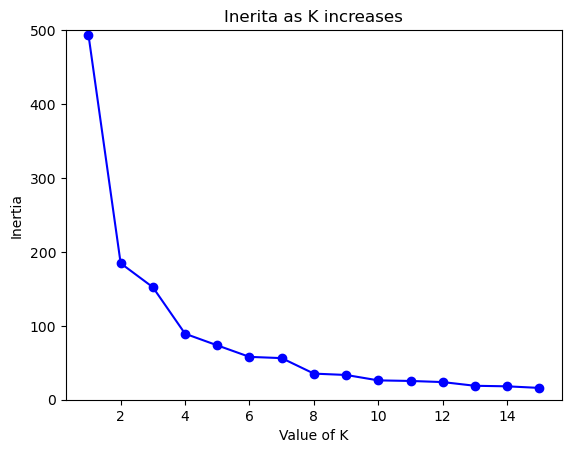

In [426]:
import matplotlib.pyplot as plt

Array = PhotoToPoints("PhotoMe.jpg",seed=4893)
finalInertias = []
for k in range(1,16):
    centers, totaInertias = KMeans(k, Array,normalize=True)
    finalInertias.append(totaInertias[-1])

plt.plot([i for i in range(1,k+1)],finalInertias,linestyle='solid', marker='o', color='blue')
plt.xlabel("Value of K")
plt.ylabel("Inertia")
plt.title("Inerita as K increases")
plt.ylim([0,500])
plt.show()

K as 8 seems the best in this curve since there is that drop from 7 to 8

[[np.float64(0.5007911936704506), np.float64(0.19208806329549355), np.float64(0.17743378052975564)], [np.float64(0.9519607843137242), np.float64(0.9744232987312569), np.float64(0.9606401384083043)], [np.float64(0.8222222222222221), np.float64(0.6431372549019607), np.float64(0.29673202614379085)], [np.float64(0.49732816203404445), np.float64(0.4974143503555269), np.float64(0.42758026287438056)], [np.float64(0.13852676205617362), np.float64(0.1270446917505739), np.float64(0.07836071365483123)], [np.float64(0.7756922616374793), np.float64(0.7186648705283635), np.float64(0.6653195629396792)], [np.float64(0.6986717267552184), np.float64(0.4959519291587602), np.float64(0.46888045540796935)], [np.float64(0.34123871770930625), np.float64(0.35978835978836), np.float64(0.20692187986305655)]]


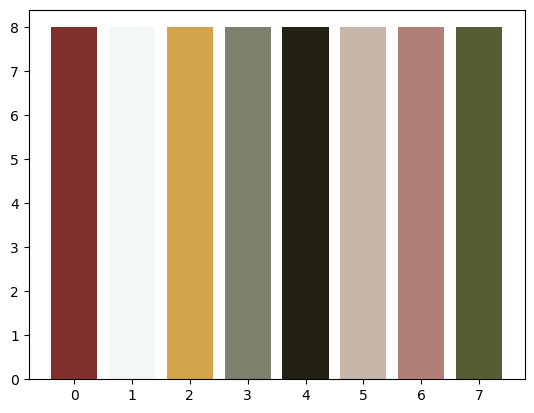

In [428]:
#reset array
Array = PhotoToPoints("PhotoMe.jpg",seed=4893)
k = 8
centers, totaInertias = KMeans(k, Array, normalize=True)

#Ploting color bars

colors = []
for centerIndex in range(len(centers)):
    for part in range(len(centers.loc[centerIndex]["data"])):
        piece = centers.loc[centerIndex]["data"][part]
        centers.loc[centerIndex]["data"][part] = piece
    colors.append((centers.loc[centerIndex]["data"]))

print(colors)
plt.bar(range(k),[k for _ in range(k)],color=colors)
plt.show()

### Attempt 2
Trying again this time with the selected amount being 20000

In [442]:
import matplotlib.pyplot as plt

Array = PhotoToPoints("PhotoMe.jpg",seed=4893, smallerSet=20000)
finalInertias = []
for k in range(1,16):
    centers, totaInertias = KMeans(k, Array,normalize=True)
    finalInertias.append(totaInertias[-1])

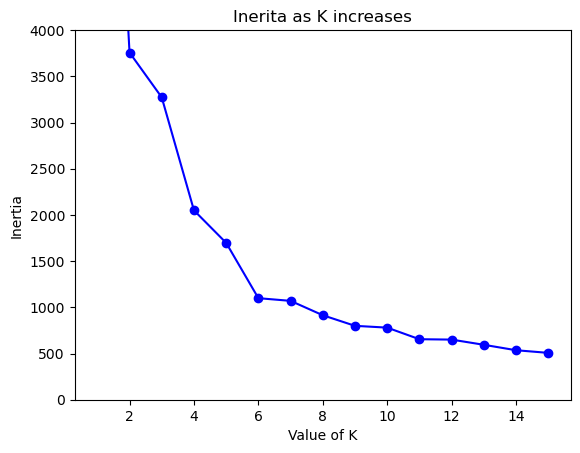

In [447]:

plt.plot([i for i in range(1,k+1)],finalInertias,linestyle='solid', marker='o', color='blue')
plt.xlabel("Value of K")
plt.ylabel("Inertia")
plt.title("Inerita as K increases")
plt.ylim([0,4000])
plt.show()

K as 11 seems the best as it follows the last "big" drop from 10

[[np.float64(0.511648965141612), np.float64(0.18522603485838846), np.float64(0.16358251633987)], [np.float64(0.9514916149227558), np.float64(0.9758913487065968), np.float64(0.9670989022240883)], [np.float64(0.8762091503267966), np.float64(0.7036165577342046), np.float64(0.2573856209150323)], [np.float64(0.5992721221329887), np.float64(0.5759713479487704), np.float64(0.5293234932349357)], [np.float64(0.1026176107031203), np.float64(0.08603456215613665), np.float64(0.055553939746480444)], [np.float64(0.43943753390684814), np.float64(0.46638475548322905), np.float64(0.29567929938773935)], [np.float64(0.6593575641638761), np.float64(0.40271002710027154), np.float64(0.3723656942451782)], [np.float64(0.2989599732837177), np.float64(0.2894613806593205), np.float64(0.27092934497399995)], [np.float64(0.8163481869640015), np.float64(0.7982191403017954), np.float64(0.7273052020540297)], [np.float64(0.8018288521905258), np.float64(0.6319139256630718), np.float64(0.598689777535144)], [np.float64(0.

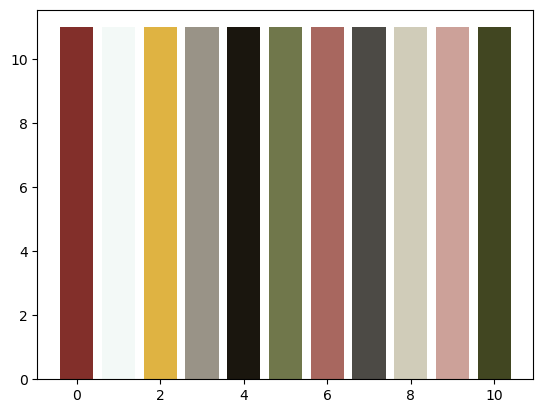

In [451]:
#reset array
# using 11 as k
Array = PhotoToPoints("PhotoMe.jpg",seed=4893,smallerSet=20000)
k = 11
centers, totaInertias = KMeans(k, Array,normalize=True)

#Ploting color bars

colors = []
for centerIndex in range(len(centers)):
    for part in range(len(centers.loc[centerIndex]["data"])):
        piece = centers.loc[centerIndex]["data"][part]
        centers.loc[centerIndex]["data"][part] = piece
    colors.append((centers.loc[centerIndex]["data"]))

print(colors)
plt.bar(range(k),[k for _ in range(k)],color=colors)
plt.show()